# Phase 2: exploration, usability and caveats

This notebook covers the plan's Phase 2 "done when": `is_usable(frame, question_type)` exists (in `src/usable.py`),
backed by figures showing why. Figures are saved to `notebooks/figures/`.

| Section | Question |
|---|---|
| 1 | How many pass moments are usable for each Tier 1 question type? |
| 2 | How good is detection coverage per match? |
| 3 | Where are usable offside moments, and how close are the calls? |
| 4 | Speed sanity check: are there tracking glitches above 12 m/s? |
| 5 | D2: do no-tracking frames cluster after shots and goals? |
| 6 | D1: does match 1953632 look normal? |
| 7 | One attacking sequence, frame by frame |

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import skillcorner
from src.load import list_matches, load_match, load_meta, get_frame
from src.moments import evaluate_all
from src.usable import QUESTION_TYPES
from src.viz import plot_frame, legend_handles

FIG = ROOT / "notebooks" / "figures"; FIG.mkdir(exist_ok=True)
QA = ROOT / "data" / "processed" / "qa"
SC = [m for m in list_matches() if not m.startswith("metrica")]
ME = [m for m in list_matches() if m.startswith("metrica")]

# chart styling: one consistent palette across figures
BLUE, ORANGE, AQUA, YELLOW, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#b9b9b3", "#2b2b2b"
TYPE_COLOR = dict(zip(QUESTION_TYPES, [BLUE, ORANGE, AQUA, YELLOW]))
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})
pd.set_option("display.width", 200)

## 1. Usable moments per Tier 1 question type

Every Tier 1 question is anchored to a **pass moment** (the frame the pass is played; the passer is the ball carrier).
For each moment and question type, `src/usable.py` checks that every answer-relevant player was detected:

| Question type | Must be detected |
|---|---|
| `offside` | passer, intended receiver, ball, second-last defender |
| `nearest_to_carrier` | carrier, ball, and every player within (nearest distance + 3 m) of the carrier |
| `defenders_goal_side` | ball, and every defender within 3 m (in x) of the ball's line |
| `overload_zone` | carrier, ball, and every player within 15 m + 3 m of the carrier |

The 3 m buffers mean an extrapolated player can only be ignored if their estimate would have to be off by more than 3 m to change the answer (DECISIONS D13).

The first run takes a few minutes; the result is cached to `data/processed/qa/tier1_moments.parquet`.

In [2]:
cache = QA / "tier1_moments.parquet"
if cache.exists():
    moments = pd.read_parquet(cache)
else:
    moments = evaluate_all(list_matches(), workers=4)
    moments.to_parquet(cache, index=False)

ucols = [f"usable_{q}" for q in QUESTION_TYPES]
summary = moments.groupby("source")[ucols].agg(["sum", "mean"])
print(f"pass moments: {len(moments):,}")
summary

pass moments: 18,956


usable_offside           usable_nearest_to_carrier           usable_defenders_goal_side           usable_overload_zone          
                       sum      mean                       sum      mean                        sum      mean                  sum      mean
source                                                                                                                                      
metrica               2884  1.000000                      2884  1.000000                       2884  1.000000                 2884  1.000000
skillcorner           6349  0.395035                     15132  0.941513                      15286  0.951095                10848  0.674963

Metrica: every pass moment is usable for every type (full-pitch tracking, no extrapolation).


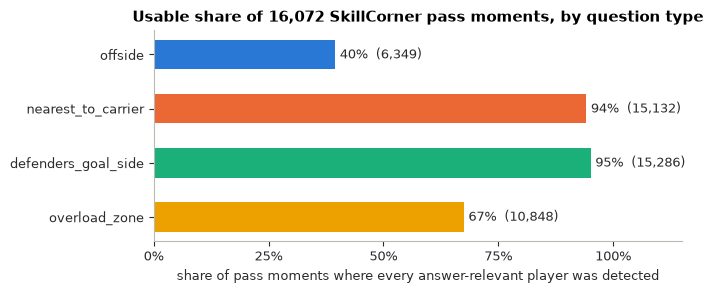

In [3]:
sc_m = moments[moments.source == "skillcorner"]
share = sc_m[ucols].mean().rename(lambda c: c.replace("usable_", ""))
counts = sc_m[ucols].sum().rename(lambda c: c.replace("usable_", ""))

fig, ax = plt.subplots(figsize=(7, 3))
y = np.arange(len(share))[::-1]
ax.barh(y, share.values, color=[TYPE_COLOR[q] for q in share.index], height=0.55)
for yi, s, n in zip(y, share.values, counts.values):
    ax.text(s + 0.01, yi, f"{s:.0%}  ({n:,})", va="center", color=INK)
ax.set_yticks(y, share.index); ax.set_xlim(0, 1.15); ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_title(f"Usable share of {len(sc_m):,} SkillCorner pass moments, by question type")
ax.set_xlabel("share of pass moments where every answer-relevant player was detected")
fig.tight_layout(); fig.savefig(FIG / "fig1_usable_by_question_type.png", dpi=150)
print("Metrica: every pass moment is usable for every type (full-pitch tracking, no extrapolation).")

## 2. Detection coverage per match

Left: share of all player rows that were detected. Right: share of pass moments usable for offside
(the strictest type). Matches are sorted by date; the five latest are marked.

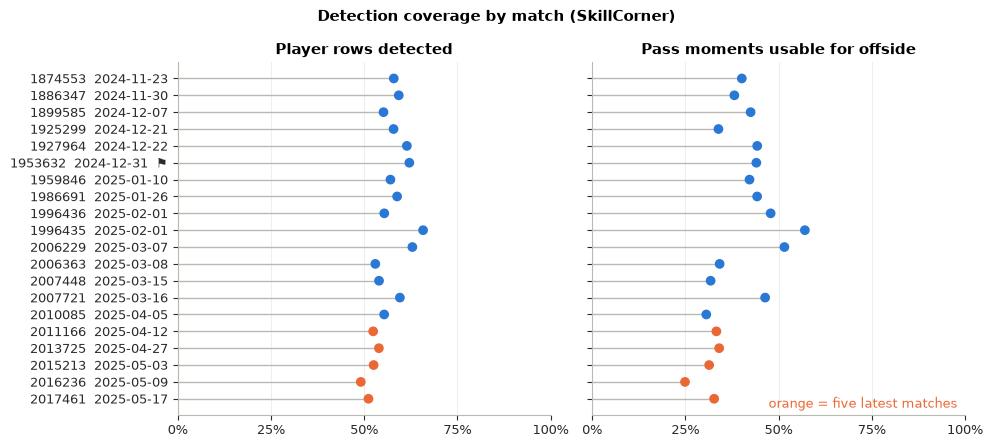

In [4]:
S = {s["match_id"]: s for s in json.loads((QA / "summary.json").read_text())}
dates = {m: load_meta(m).get("date_time", "") for m in SC}
order = sorted(SC, key=lambda m: dates[m])
det_share = [S[m]["share_player_rows_detected"] for m in order]
off_share = sc_m.groupby("match").usable_offside.mean().reindex(order).values
late = set(order[-5:])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
y = np.arange(len(order))[::-1]
for ax, vals, title in ((axes[0], det_share, "Player rows detected"),
                        (axes[1], off_share, "Pass moments usable for offside")):
    cols = [ORANGE if m in late else BLUE for m in order]
    ax.scatter(vals, y, color=cols, s=36, zorder=3)
    ax.hlines(y, 0, vals, color=GREY, lw=1, zorder=2)
    ax.set_xlim(0, 1); ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
    ax.set_title(title); ax.grid(axis="x", color="#eeeeea", zorder=0)
axes[0].set_yticks(y, [f"{m}  {dates[m][:10]}" + ("  ⚑" if m == "1953632" else "") for m in order])
axes[1].text(0.98, 0.02, "orange = five latest matches", transform=axes[1].transAxes, ha="right", color=ORANGE)
fig.suptitle("Detection coverage by match (SkillCorner)", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "fig2_detection_by_match.png", dpi=150)

## 3. Where are usable offside moments, and how close are the calls?

Offside-possible passes only (receiver in the opponents' half and ahead of the ball, not a restart).

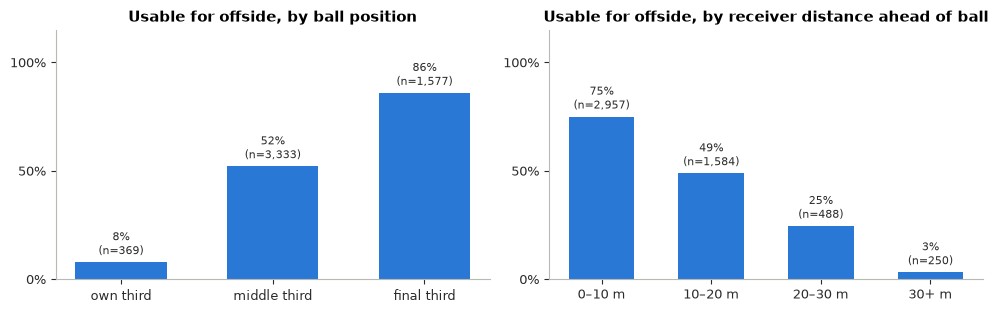

In [5]:
rel = sc_m[sc_m.offside_possible].copy()
rel["ball_zone"] = pd.cut(rel.x_ball, [-60, -17.5, 17.5, 60], labels=["own third", "middle third", "final third"])
rel["ahead"] = pd.cut(rel.x_receiver - rel.x_ball, [0, 10, 20, 30, 100], labels=["0–10 m", "10–20 m", "20–30 m", "30+ m"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, col, title in ((axes[0], "ball_zone", "by ball position"),
                       (axes[1], "ahead", "by receiver distance ahead of ball")):
    g = rel.groupby(col, observed=True).usable_offside.agg(["mean", "size"])
    x = np.arange(len(g))
    ax.bar(x, g["mean"], color=BLUE, width=0.6)
    for xi, (mval, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(xi, mval + 0.02, f"{mval:.0%}\n(n={n:,})", ha="center", va="bottom", color=INK, fontsize=8)
    ax.set_xticks(x, g.index); ax.set_ylim(0, 1.15); ax.set_yticks([0, .5, 1], ["0%", "50%", "100%"])
    ax.set_title(f"Usable for offside, {title}")
fig.tight_layout(); fig.savefig(FIG / "fig3_offside_usable_bias.png", dpi=150)

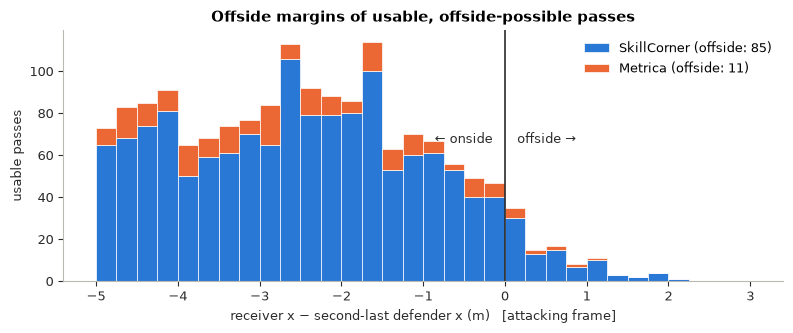

In [6]:
me_m = moments[moments.source == "metrica"]
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.arange(-5, 3.01, 0.25)
data, labels = [], []
for src, d in (("SkillCorner", sc_m), ("Metrica", me_m)):
    u = d[d.offside_possible & d.usable_offside & d.offside_margin_m.between(-5, 3)]
    data.append(u.offside_margin_m); labels.append(f"{src} (offside: {int(u.offside.sum())})")
ax.hist(data, bins=bins, stacked=True, color=[BLUE, ORANGE], label=labels, edgecolor="white", linewidth=0.5)
ax.axvline(0, color=INK, lw=1.2)
top = ax.get_ylim()[1]
ax.text(0.15, top * 0.55, "offside →", color=INK)
ax.text(-0.15, top * 0.55, "← onside", color=INK, ha="right")
ax.set_xlabel("receiver x − second-last defender x (m)   [attacking frame]")
ax.set_ylabel("usable passes")
ax.set_title("Offside margins of usable, offside-possible passes")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "fig4_offside_margins.png", dpi=150)

## 4. Speed sanity check

Speed between consecutive frames for every player (10 fps SkillCorner, 25 fps Metrica).
Anything above 12 m/s (a sprint peaks around 10–11 m/s) is flagged as a likely tracking glitch.

In [7]:
def speed_stats(m):
    df = load_match(m, columns=["period", "frame_id", "object_type", "player_id", "x_m", "y_m", "is_detected", "source"])
    p = df[(df.object_type == "player") & df.x_m.notna()].sort_values(["player_id", "period", "frame_id"])
    fps = 10 if p.source.iloc[0] == "skillcorner" else 25
    same = (p.player_id == p.player_id.shift()) & (p.period == p.period.shift()) & (p.frame_id - p.frame_id.shift() == 1)
    v = np.hypot(p.x_m.diff(), p.y_m.diff()) * fps
    p = p.assign(speed=v.where(same))
    p = p[p.speed.notna()]
    det = p.is_detected.fillna(False).astype(bool)
    return dict(match=m, steps=len(p), p99_speed=p.speed.quantile(0.99), max_speed=p.speed.max(),
                over12=int((p.speed > 12).sum()), over12_share=(p.speed > 12).mean(),
                over12_detected=int(((p.speed > 12) & det).sum()), over12_extrapolated=int(((p.speed > 12) & ~det).sum()))

speeds = pd.DataFrame([speed_stats(m) for m in list_matches()]).set_index("match")
speeds.style.format({"p99_speed": "{:.1f}", "max_speed": "{:.1f}", "over12_share": "{:.3%}", "steps": "{:,}"})

,steps,p99_speed,max_speed,over12,over12_share,over12_detected,over12_extrapolated
match,,,,,,,
1874553,"971,982",6.4,12.5,5,0.001%,5,0
1886347,"954,646",6.4,14.0,17,0.002%,8,9
1899585,"893,376",6.5,19.2,30,0.003%,9,21
1925299,"1,053,558",6.0,12.1,1,0.000%,1,0
1927964,"983,356",6.3,12.6,5,0.001%,5,0
1953632,"964,502",6.2,10.8,0,0.000%,0,0
1959846,"938,784",6.6,14.3,10,0.001%,3,7
1986691,"945,868",6.4,18.6,13,0.001%,10,3
1996435,"956,118",6.4,99.4,3,0.000%,0,3


## 5. D2: do no-tracking frames cluster after shots and goals?

For every SkillCorner shot (a possession ending in a shot), the share of frames with **no tracking at all** at each
second from 20 s before to 60 s after the shot, compared with the match-wide baseline. Goals (possessions whose next
interruption is `goal_for`) are shown separately.

baseline no-tracking share: 25.6%
kind       goal shot (no goal)
t                             
-10.0  0.098361       0.112069
 0.0        0.0            0.0
 5.0        0.0       0.002151
 10.0  0.967213       0.607759
 20.0  0.983607       0.587852
 30.0  0.983607       0.382609
 45.0  0.934426       0.238512
 60.0  0.852459       0.260965


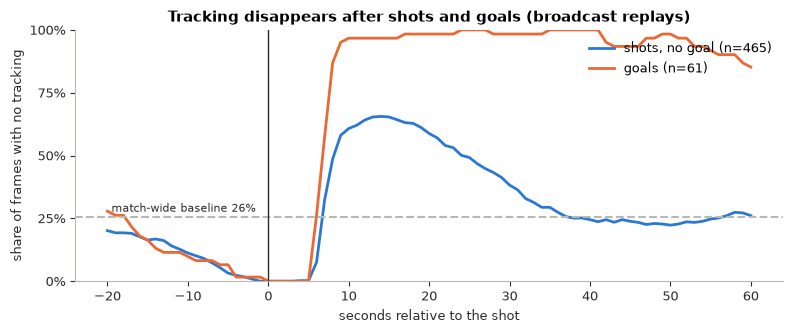

In [8]:
rows = []
offsets = np.arange(-200, 601, 10)        # frames, 10 fps -> -20 s .. +60 s
for m in SC:
    df = load_match(m, columns=["frame_id", "object_type", "x_m"])
    has_players = df[df.object_type == "player"].groupby("frame_id").size().reindex(df.frame_id.unique(), fill_value=0) > 0
    ev = skillcorner.load_dynamic_events(m)
    shots = ev[(ev.event_type == "player_possession") & (ev.end_type == "shot")]
    for s in shots.itertuples():
        f0 = int(s.frame_end)
        kind = "goal" if s.game_interruption_after == "goal_for" else "shot (no goal)"
        idx = f0 + offsets
        vals = has_players.reindex(idx)            # NaN where the offset falls outside a period
        rows += [dict(match=m, kind=kind, t=o / 10, no_tracking=(not v) if pd.notna(v) else np.nan)
                 for o, v in zip(offsets, vals.values)]
    rows += [dict(match=m, kind="baseline", t=np.nan, no_tracking=float((~has_players).mean()))]

d2 = pd.DataFrame(rows)
baseline = d2[d2.kind == "baseline"].no_tracking.mean()
curve = d2[d2.kind != "baseline"].dropna(subset=["no_tracking"]).groupby(["kind", "t"]).no_tracking.mean().unstack(0)
n_shots = d2[(d2.kind == "shot (no goal)") & (d2.t == 0)].shape[0]
n_goals = d2[(d2.kind == "goal") & (d2.t == 0)].shape[0]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(curve.index, curve["shot (no goal)"], color=BLUE, lw=2, label=f"shots, no goal (n={n_shots})")
ax.plot(curve.index, curve["goal"], color=ORANGE, lw=2, label=f"goals (n={n_goals})")
ax.axhline(baseline, color=GREY, lw=1.5, ls="--")
ax.text(-19.5, baseline + 0.02, f"match-wide baseline {baseline:.0%}", color=INK, fontsize=8)
ax.axvline(0, color=INK, lw=1)
ax.set_xlabel("seconds relative to the shot"); ax.set_ylabel("share of frames with no tracking")
ax.set_ylim(0, 1); ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_title("Tracking disappears after shots and goals (broadcast replays)")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout(); fig.savefig(FIG / "fig5_no_tracking_after_shots.png", dpi=150)
print(f"baseline no-tracking share: {baseline:.1%}")
print(curve.loc[[-10.0, 0.0, 5.0, 10.0, 20.0, 30.0, 45.0, 60.0]].round(2))

## 6. D1: does match 1953632 look normal?

It is listed as `not_started` in both SkillCorner metadata files but has full data. Compare it with the other
19 matches, then look at a few frames.

In [9]:
stats = pd.DataFrame({"player rows detected": {m: S[m]["share_player_rows_detected"] for m in SC}})
stats["usable offside"] = sc_m.groupby("match").usable_offside.mean()
stats["pass moments"] = sc_m.groupby("match").size()
stats["goals in meta"] = {m: f"{load_meta(m)['score']['home']}-{load_meta(m)['score']['away']}" for m in SC}
others = stats.drop(index="1953632")
cmp = pd.DataFrame({"1953632": stats.loc["1953632", ["player rows detected", "usable offside", "pass moments"]],
                    "others: min": others[["player rows detected", "usable offside", "pass moments"]].min(),
                    "others: median": others[["player rows detected", "usable offside", "pass moments"]].median(),
                    "others: max": others[["player rows detected", "usable offside", "pass moments"]].max()})
print("score in match.json:", stats.loc["1953632", "goals in meta"])
cmp

score in match.json: 1-1


,1953632,others: min,others: median,others: max
player rows detected,0.621138,0.490984,0.553949,0.657990
usable offside,0.440462,0.249089,0.381455,0.570615
pass moments,865.000000,630.000000,823.000000,996.000000


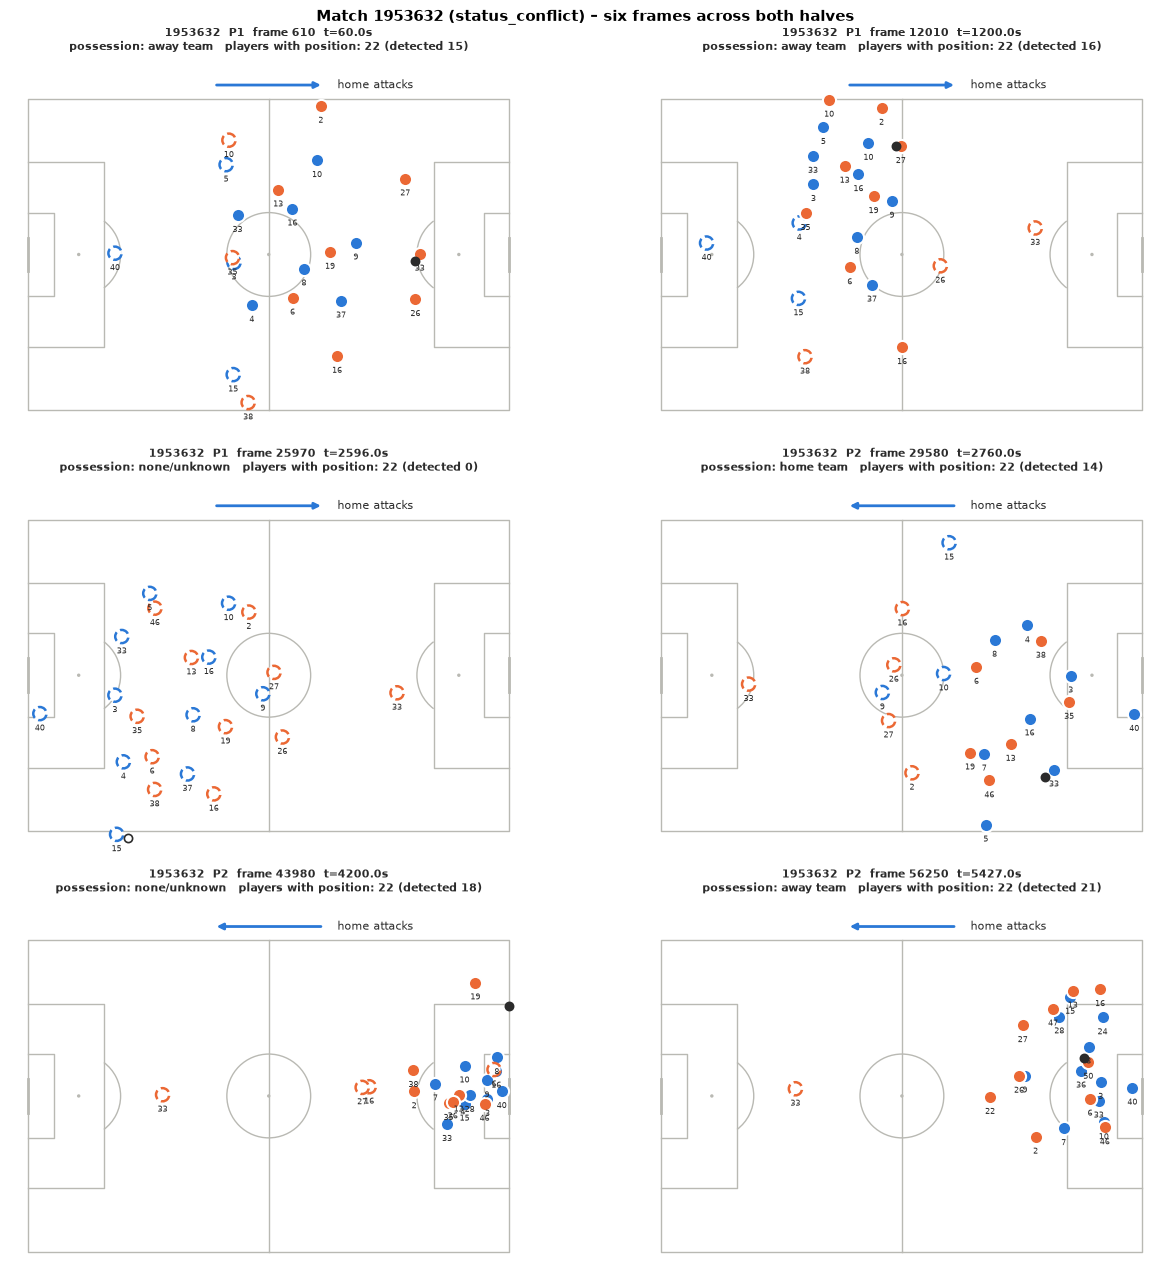

In [10]:
meta = load_meta("1953632")
p1, p2 = meta["periods"]
picks = [p1["start_frame"] + 600, p1["start_frame"] + 12000, p1["end_frame"] - 3000,
         p2["start_frame"] + 600, p2["start_frame"] + 15000, p2["end_frame"] - 3000]
fig, axes = plt.subplots(3, 2, figsize=(13, 13))
for ax, fid in zip(axes.ravel(), picks):
    # step forward to the next frame that has players
    for k in range(0, 600, 10):
        fr = get_frame("1953632", fid + k)
        if (fr.object_type == "player").sum() >= 10:
            plot_frame("1953632", fid + k, ax=ax); break
fig.suptitle("Match 1953632 (status_conflict) – six frames across both halves", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "d1_match_1953632_frames.png", dpi=110)

## 7. One attacking sequence, frame by frame

The goal with the best detection coverage in the 5 s before the shot, plotted at 1 s intervals.
Compare against highlights if you can find the match on YouTube (date and teams are in the title).

1927964: Western Sydney v Wellington P FC (2024-12-22), goal by D. Scicluna (Western Sydney) at frame 57232, detected share 82%


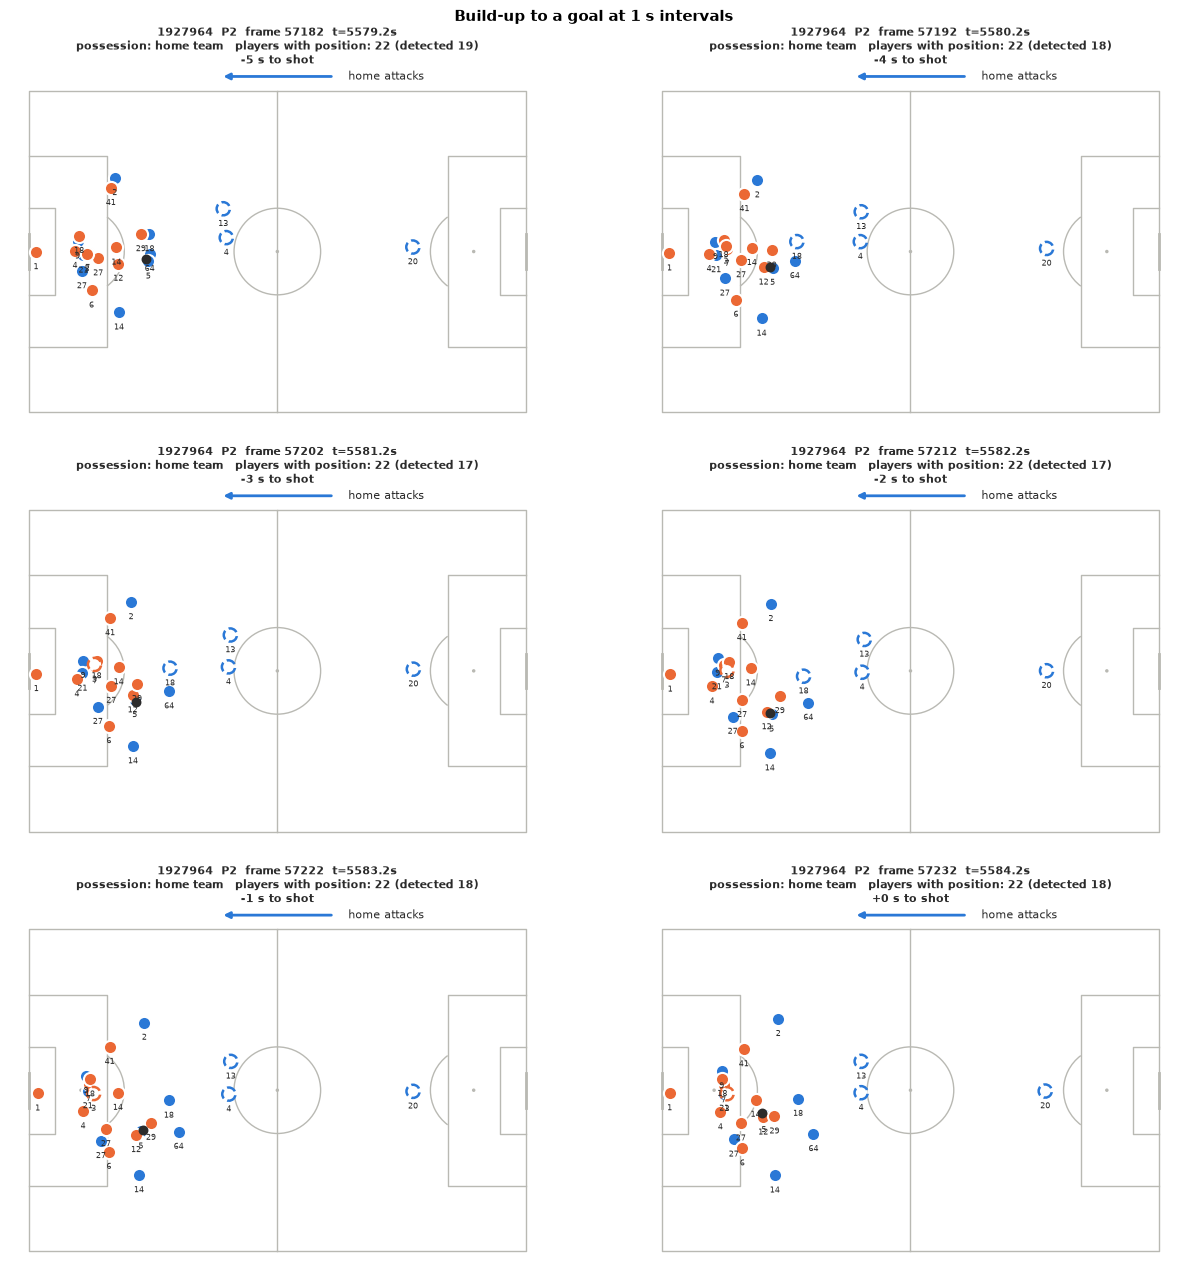

In [11]:
cands = []
for m in SC:
    ev = skillcorner.load_dynamic_events(m)
    goals = ev[(ev.event_type == "player_possession") & (ev.end_type == "shot") & (ev.game_interruption_after == "goal_for")]
    df = load_match(m, columns=["frame_id", "object_type", "is_detected"])
    det = df[df.object_type == "player"].groupby("frame_id").is_detected.mean()
    for g in goals.itertuples():
        window = det.reindex(range(int(g.frame_end) - 50, int(g.frame_end) + 1)).dropna()
        if len(window) > 40:
            cands.append((window.mean(), m, int(g.frame_end), g.player_name, g.team_shortname))
best = max(cands)
_, gm, gf, scorer, team = best
gmeta = load_meta(gm)
print(f"{gm}: {gmeta['teams']['home']['short_name']} v {gmeta['teams']['away']['short_name']} "
      f"({gmeta['date_time'][:10]}), goal by {scorer} ({team}) at frame {gf}, detected share {best[0]:.0%}")

fig, axes = plt.subplots(3, 2, figsize=(13, 13))
for ax, k in zip(axes.ravel(), range(-50, 1, 10)):
    plot_frame(gm, gf + k, ax=ax)
    ax.set_title(ax.get_title() + f"\n{k / 10:+.0f} s to shot", fontsize=8)
fig.suptitle("Build-up to a goal at 1 s intervals", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "fig6_attacking_sequence.png", dpi=110)

## Notes (fill in)

- Usable share by question type:
- Detection coverage / late-season matches:
- Speed glitches (how many, detected vs extrapolated):
- D2 (no tracking after shots/goals):
- D1 (match 1953632): keep / exclude, and why: